# DQN - LunarLander

Here we build a DQN agent for LunarLander. We start with random actions to get a score to compare with the trained agent later.

## Imports and settings

We keep the seed and the main settings here. The environment and the actions also get a seed so we can repeat the same tests.

In [1]:
import random
import time
from pathlib import Path

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
RANDOM_EPISODES = 100
HIDDEN_SIZE = 64
BUFFER_CAPACITY = 100_000
BATCH_SIZE = 64
EPSILON_START = 1.0
EPSILON_END = 0.05
EPSILON_DECAY_STEPS = 100_000
TARGET_UPDATE_EVERY = 1_000
GAMMA = 0.99
LEARNING_RATE = 1e-3
TRAIN_EPISODES = 20

torch.set_num_threads(1)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Seed:", SEED)


Seed: 42


## Creating the environment

Here we create LunarLander without a window so the tests run faster. We read the state size and the number of actions from the environment.

In [2]:
env = gym.make("LunarLander-v3", render_mode=None)
state, info = env.reset(seed=SEED)

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Number of actions:", action_size)
print("Initial state:", state)


State size: 8
Number of actions: 4
Initial state: [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]


## Random agent

We play 100 episodes with random actions and keep the score, length and ending of each episode.

`terminated` means the episode really ended. `truncated` means it reached the time limit. Both stop the loop, but we need to keep the difference when we add learning.

In [3]:
scores = []
episode_lengths = []
end_reasons = []

try:
    for episode in range(RANDOM_EPISODES):
        seed = SEED + episode
        state, info = env.reset(seed=seed)
        env.action_space.seed(seed)
        total_reward = 0.0
        steps = 0
        done = False

        while not done:
            action = env.action_space.sample()
            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            steps += 1
            done = terminated or truncated

        # Check why the episode ended.
        if not env.unwrapped.lander.awake:
            reason = "at rest"
        elif env.unwrapped.game_over:
            reason = "crash"
        elif abs(state[0]) >= 1:
            reason = "out of bounds"
        else:
            reason = "time limit"

        scores.append(total_reward)
        episode_lengths.append(steps)
        end_reasons.append(reason)
finally:
    env.close()


## First results

Let's print the mean score, the standard deviation and the episode endings. A lander at rest is not enough to call it a good landing, so we also need to look at the score.

In [4]:
print(f"Episodes: {len(scores)}")
print(f"Mean score: {np.mean(scores):.2f}")
print(f"Standard deviation: {np.std(scores):.2f}")
print(f"Mean episode length: {np.mean(episode_lengths):.1f}")

for reason in ["crash", "out of bounds", "at rest", "time limit"]:
    print(f"{reason}: {end_reasons.count(reason)}")


Episodes: 100
Mean score: -193.03
Standard deviation: 115.39
Mean episode length: 90.1
crash: 91
out of bounds: 9
at rest: 0
time limit: 0


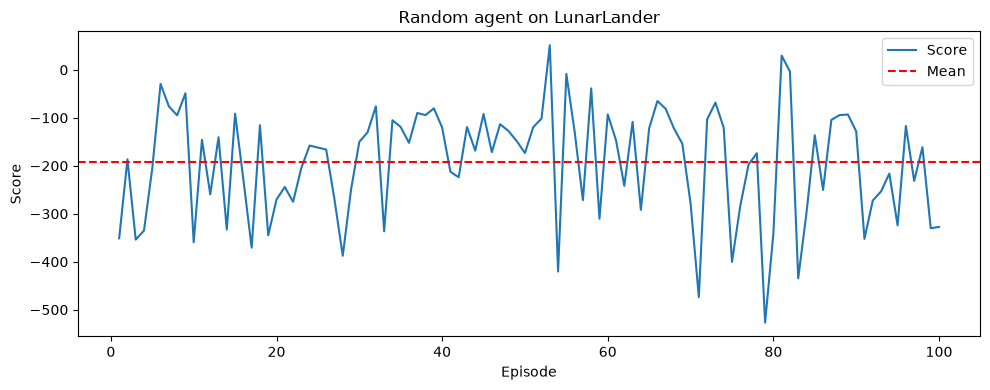

In [5]:
episodes = np.arange(1, len(scores) + 1)

plt.figure(figsize=(10, 4))
plt.plot(episodes, scores, label="Score")
plt.axhline(np.mean(scores), color="red", linestyle="--", label="Mean")
plt.xlabel("Episode")
plt.ylabel("Score")
plt.title("Random agent on LunarLander")
plt.legend()
plt.tight_layout()
plt.show()


## Random agent results

The mean score is -193.03 over 100 episodes, with a standard deviation of 115.39. We get 91 crashes and 9 exits from the screen.

This gives us a starting score. The random agent does not solve the task.

## DQN network

We start with two hidden layers of 64 neurons. This keeps the first network small for an input of 8 state values.

The network returns one Q-value per action. Each value estimates the total reward we can get by taking that action and continuing to play.

ReLU between the layers lets the network learn non-linear relations. The last layer has no activation because Q-values can be negative and are not probabilities.

In [6]:
class DQN(nn.Module):
    def __init__(self, state_size, action_size, hidden_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size),
        )

    def forward(self, state):
        return self.network(state)


q_network = DQN(state_size, action_size, HIDDEN_SIZE)
print(q_network)


DQN(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=4, bias=True)
  )
)


## Checking the output

Let's pass one state as a float32 tensor and check the output. `torch.no_grad()` runs this test without tracking gradients, and `argmax()` gives the action with the highest value.

The weights are still random here. The network has not learned yet.

In [7]:
state_tensor = torch.tensor(state, dtype=torch.float32)

with torch.no_grad():
    q_values = q_network(state_tensor)

best_action = q_values.argmax().item()

print("Input shape:", state_tensor.shape)
print("Output shape:", q_values.shape)
print("Action values:", q_values)
print("Action with the highest value:", best_action)


Input shape: torch.Size([8])
Output shape: torch.Size([4])
Action values: tensor([ 0.0419,  0.1327,  0.0468, -0.0738])
Action with the highest value: 1


## Replay buffer

The buffer stores the state, action, reward, next state and real ending of each step. We keep up to 100,000 experiences to reuse past episodes.

When the buffer is full, new experiences replace the oldest ones. `position` moves to the next slot and goes back to zero at the end.

We will sample batches of 64 experiences at random to mix steps from different episodes. We store `terminated` as the ending flag: a time limit stops the loop but still allows future rewards.

In [8]:
class ReplayBuffer:
    def __init__(self, capacity):
        if capacity < 1:
            raise ValueError("Capacity must be positive")
        self.capacity = capacity
        self.buffer = []
        self.position = 0

    def add(self, state, action, reward, next_state, terminated):
        transition = (state, action, reward, next_state, terminated)
        if len(self.buffer) < self.capacity:
            self.buffer.append(transition)
        else:
            self.buffer[self.position] = transition
        self.position = (self.position + 1) % self.capacity

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, terminateds = zip(*batch)
        return (
            torch.tensor(np.array(states), dtype=torch.float32),
            torch.tensor(actions, dtype=torch.int64),
            torch.tensor(rewards, dtype=torch.float32),
            torch.tensor(np.array(next_states), dtype=torch.float32),
            torch.tensor(terminateds, dtype=torch.float32),
        )

    def __len__(self):
        return len(self.buffer)


## Checking the capacity

Here we put 5 made-up experiences in a buffer with only 3 places. Their rewards go from 0 to 4, so only 2, 3 and 4 should remain.

In [9]:
test_buffer = ReplayBuffer(3)
test_state = np.zeros(state_size, dtype=np.float32)

for reward in range(5):
    test_buffer.add(test_state, 0, reward, test_state, False)

remaining_rewards = sorted(transition[2] for transition in test_buffer.buffer)
print("Stored experiences:", len(test_buffer))
print("Rewards left in the buffer:", remaining_rewards)


Stored experiences: 3
Rewards left in the buffer: [2, 3, 4]


## Filling the buffer

We play one random episode and store each transition. This is just to check that the buffer works with the environment. There is no learning in this loop yet.

In [10]:
replay_buffer = ReplayBuffer(BUFFER_CAPACITY)
env = gym.make("LunarLander-v3", render_mode=None)
state, info = env.reset(seed=SEED)
env.action_space.seed(SEED)
done = False

try:
    while not done:
        action = env.action_space.sample()
        next_state, reward, terminated, truncated, info = env.step(action)
        replay_buffer.add(state, action, reward, next_state, terminated)
        state = next_state
        done = terminated or truncated
finally:
    env.close()

print("Experiences in the replay buffer:", len(replay_buffer))


Experiences in the replay buffer: 123


## Sampling a batch

We check that the buffer has enough experiences before sampling. The states have shape `(batch size, state size)`.

Actions are integers. Rewards, states and ending flags are floats, with 0 or 1 for the flags. These tensors will be used to calculate the DQN loss.

In [11]:
if len(replay_buffer) >= BATCH_SIZE:
    states, actions, rewards, next_states, terminateds = replay_buffer.sample(BATCH_SIZE)

    print("States:", states.shape, states.dtype)
    print("Actions:", actions.shape, actions.dtype)
    print("Rewards:", rewards.shape, rewards.dtype)
    print("Next states:", next_states.shape, next_states.dtype)
    print("Terminations:", terminateds.shape, terminateds.dtype)
else:
    print("Not enough experiences to sample a batch")


States: torch.Size([64, 8]) torch.float32
Actions: torch.Size([64]) torch.int64
Rewards: torch.Size([64]) torch.float32
Next states: torch.Size([64, 8]) torch.float32
Terminations: torch.Size([64]) torch.float32


## Choosing an action

Epsilon is the chance of picking a random action. Otherwise, we take the action with the highest Q-value.

With epsilon at 1, all choices are random. With epsilon at 0, we always follow the network. We will use 0 for evaluation.

For training, epsilon goes from 1 to 0.05 over 100,000 steps. We use a linear decrease because it is easy to follow and leaves more exploration at the start. The minimum keeps a 5% chance of exploring. These are starting values to test during training.

In [12]:
def get_epsilon(step):
    if step >= EPSILON_DECAY_STEPS:
        return EPSILON_END
    decrease = (EPSILON_START - EPSILON_END) * step / EPSILON_DECAY_STEPS
    return EPSILON_START - decrease


def select_action(state, epsilon):
    if random.random() < epsilon:
        return random.randrange(action_size)

    state_tensor = torch.tensor(state, dtype=torch.float32)
    with torch.no_grad():
        q_values = q_network(state_tensor)
    return q_values.argmax().item()


## Checking epsilon

The step counter will cover all training episodes. Here we check the start, middle and end of the decrease, then a later step. Epsilon should stay at 0.05 after 100,000 steps.

In [13]:
test_steps = [0, EPSILON_DECAY_STEPS // 2, EPSILON_DECAY_STEPS, 2 * EPSILON_DECAY_STEPS]

for step in test_steps:
    print(f"Step {step}: epsilon = {get_epsilon(step):.3f}")


Step 0: epsilon = 1.000
Step 50000: epsilon = 0.525
Step 100000: epsilon = 0.050
Step 200000: epsilon = 0.050


## Checking both choices

Here we repeat the choice on the same state. With epsilon at 1, the actions can change. With epsilon at 0, they should match the highest Q-value.

We check that random actions are valid and that the network choice matches `argmax()`. The network is still untrained, so its choice is not a reliable landing strategy yet.

In [14]:
random.seed(SEED)

with torch.no_grad():
    test_values = q_network(torch.tensor(state, dtype=torch.float32))
expected_action = test_values.argmax().item()

random_actions = [select_action(state, epsilon=1.0) for _ in range(10)]
greedy_actions = [select_action(state, epsilon=0.0) for _ in range(10)]

print("With epsilon = 1:", random_actions)
print("With epsilon = 0:", greedy_actions)
print("Action with the highest Q-value:", expected_action)

assert all(0 <= action < action_size for action in random_actions)
assert greedy_actions == [expected_action] * 10
print("Both action selection tests passed")


With epsilon = 1: [0, 1, 0, 0, 0, 1, 0, 3, 2, 0]
With epsilon = 0: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Action with the highest Q-value: 0
Both action selection tests passed


## Target network

The target network is a copy of `q_network`. We will use it to estimate future Q-values when we calculate the loss.

Its weights stay fixed between copies. This gives the main network a stable target while it learns. We copy the main weights at the start and every 1,000 learning updates.

We start with a fixed interval so the main network can change for a while before the target follows. We will check this setting during training. The counter here counts weight updates, while epsilon uses environment steps.

In [15]:
target_network = DQN(state_size, action_size, HIDDEN_SIZE)
target_network.load_state_dict(q_network.state_dict())
target_network.eval()
target_network.requires_grad_(False)


def update_target_network(learning_step):
    if learning_step > 0 and learning_step % TARGET_UPDATE_EVERY == 0:
        target_network.load_state_dict(q_network.state_dict())


## Checking the copy

Both networks should start with the same weights. The target is in evaluation mode and does not track gradients for its weights.

In [16]:
same_weights = all(
    torch.equal(main, target)
    for main, target in zip(q_network.parameters(), target_network.parameters())
)
target_has_gradients = any(weight.requires_grad for weight in target_network.parameters())

assert same_weights
assert not target_has_gradients
assert not target_network.training
print("Same weights at the start:", same_weights)
print("Target weights need gradients:", target_has_gradients)


Same weights at the start: True
Target weights need gradients: False


## Checking the update timing

Here we change the main network's last bias just for the test. The target must stay unchanged before the interval, then match the main network at the interval.

We restore the original weights at the end. This is only a copy test, not a learning update.

In [17]:
main_bias = q_network.network[-1].bias
saved_bias = main_bias.detach().clone()
target_bias = target_network.network[-1].bias
target_before = target_bias.detach().clone()

try:
    with torch.no_grad():
        main_bias.add_(1.0)

    update_target_network(TARGET_UPDATE_EVERY - 1)
    assert torch.equal(target_bias, target_before)
    print("Target stays fixed before the interval")

    update_target_network(TARGET_UPDATE_EVERY)
    assert torch.equal(target_bias, main_bias)
    print("Target matches the main network at the interval")
finally:
    with torch.no_grad():
        main_bias.copy_(saved_bias)
    target_network.load_state_dict(q_network.state_dict())


Target stays fixed before the interval
Target matches the main network at the interval


## Learning target

The target is the reward plus the discounted best value of the next state. Gamma controls how much we count future rewards. We start at 0.99 to keep future rewards important.

A real ending uses only the reward. A time limit keeps the future estimate because the lander could have continued.

For example, a reward of 10 and a next-state value of 20 give a target of 29.8 with gamma at 0.99. If the episode really ended, the target is 10.

In [18]:
def bellman_targets(rewards, next_values, terminateds, gamma):
    return rewards + gamma * next_values * (1 - terminateds)


example_targets = bellman_targets(
    torch.tensor([10.0, 10.0, 10.0]),
    torch.tensor([20.0, 20.0, 20.0]),
    torch.tensor([0.0, 1.0, 0.0]),
    gamma=0.99,
)
assert torch.allclose(example_targets, torch.tensor([29.8, 10.0, 29.8]))
print("Targets for continuing, terminated and time-limited steps:", example_targets)


Targets for continuing, terminated and time-limited steps: tensor([29.8000, 10.0000, 29.8000])


## Preparing a short run

We start again with seed 42, a fresh network and an empty buffer. This keeps the checks above separate from the training run.

The budget is only 20 episodes to check the learning code. Adam uses a learning rate of 0.001 as a first small step size. The loss is MSE, as required by the project. We use one CPU thread for this small network.

In [19]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

q_network = DQN(state_size, action_size, HIDDEN_SIZE)
q_network.train()
target_network.load_state_dict(q_network.state_dict())
replay_buffer = ReplayBuffer(BUFFER_CAPACITY)
optimizer = torch.optim.Adam(q_network.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()

initial_weights = [weight.detach().clone() for weight in q_network.parameters()]
training_scores = []
training_lengths = []
training_losses = []
training_epsilons = []
training_endings = []
total_steps = 0
learning_steps = 0


## Learning from a batch

Here we take 64 experiences from the buffer. `gather()` keeps the Q-value of the action that was actually taken.

The target network estimates the next-state values without gradients. MSE compares the predictions with the targets. Then Adam updates only the main network's weights.

In [20]:
def learn_from_buffer():
    states, actions, rewards, next_states, terminateds = replay_buffer.sample(BATCH_SIZE)
    predicted_values = q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    with torch.no_grad():
        next_values = target_network(next_states).max(dim=1).values
        targets = bellman_targets(rewards, next_values, terminateds, GAMMA)

    loss = loss_fn(predicted_values, targets)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item()


def episode_end_reason(env, state):
    if not env.unwrapped.lander.awake:
        return "at rest"
    if env.unwrapped.game_over:
        return "crash"
    if abs(state[0]) >= 1:
        return "out of bounds"
    return "time limit"


## First 20 training episodes

This is the same episode loop as before, with experience storage and learning added. We start learning when the buffer has at least 64 experiences.

Epsilon follows the total number of environment steps. The target copy follows the number of learning updates. We keep the score, length and ending of every episode, plus the loss of each update.

In [21]:
env = gym.make("LunarLander-v3", render_mode=None)
training_start = time.perf_counter()

try:
    for episode in range(TRAIN_EPISODES):
        state, info = env.reset(seed=SEED + episode)
        total_reward = 0.0
        steps = 0
        done = False

        while not done:
            epsilon = get_epsilon(total_steps)
            action = select_action(state, epsilon)
            next_state, reward, terminated, truncated, info = env.step(action)
            replay_buffer.add(state, action, reward, next_state, terminated)
            state = next_state
            total_reward += reward
            steps += 1
            total_steps += 1

            if len(replay_buffer) >= BATCH_SIZE:
                training_losses.append(learn_from_buffer())
                learning_steps += 1
                update_target_network(learning_steps)

            done = terminated or truncated

        reason = episode_end_reason(env, state)
        training_scores.append(total_reward)
        training_lengths.append(steps)
        training_epsilons.append(get_epsilon(total_steps))
        training_endings.append(reason)
        print(f"Episode {episode + 1}: score = {total_reward:.2f}, steps = {steps}, end = {reason}")
finally:
    env.close()

training_seconds = time.perf_counter() - training_start


Episode 1: score = -196.76, steps = 114, end = crash
Episode 2: score = -106.95, steps = 76, end = crash
Episode 3: score = -434.94, steps = 92, end = out of bounds
Episode 4: score = -153.29, steps = 86, end = crash
Episode 5: score = -65.42, steps = 61, end = crash


Episode 6: score = -122.65, steps = 112, end = crash
Episode 7: score = -95.03, steps = 86, end = crash
Episode 8: score = -141.73, steps = 99, end = crash
Episode 9: score = -135.12, steps = 68, end = crash
Episode 10: score = -254.45, steps = 110, end = crash
Episode 11: score = -120.65, steps = 63, end = crash


Episode 12: score = -24.15, steps = 91, end = crash
Episode 13: score = -126.54, steps = 83, end = crash
Episode 14: score = -100.82, steps = 83, end = crash
Episode 15: score = -124.28, steps = 62, end = crash
Episode 16: score = -262.45, steps = 105, end = out of bounds
Episode 17: score = -113.23, steps = 77, end = crash


Episode 18: score = -357.01, steps = 83, end = crash
Episode 19: score = -138.75, steps = 135, end = crash
Episode 20: score = -137.43, steps = 107, end = crash


## Checking the short run

We check that learning happened, that the loss stayed finite and that the main weights changed. The target weights should still have no gradients.

These are training scores with exploration. Twenty episodes are only a first check, so they do not show whether the agent can land reliably.

In [22]:
weights_changed = any(
    not torch.equal(before, after)
    for before, after in zip(initial_weights, q_network.parameters())
)
assert learning_steps > 0
assert np.all(np.isfinite(training_losses))
assert weights_changed
assert all(weight.grad is None for weight in target_network.parameters())

print("Training episodes:", len(training_scores))
print("Environment steps:", total_steps)
print("Learning updates:", learning_steps)
print("Target copies during training:", learning_steps // TARGET_UPDATE_EVERY)
print("Main weights changed:", weights_changed)
print(f"Mean training score: {np.mean(training_scores):.2f}")
print(f"Final epsilon: {get_epsilon(total_steps):.3f}")
print(f"Training time: {training_seconds:.1f} seconds")
for reason in ["crash", "out of bounds", "at rest", "time limit"]:
    print(f"{reason}: {training_endings.count(reason)}")


Training episodes: 20
Environment steps: 1793
Learning updates: 1730
Target copies during training: 1
Main weights changed: True
Mean training score: -160.58
Final epsilon: 0.983
Training time: 0.9 seconds
crash: 18
out of bounds: 2
at rest: 0
time limit: 0


## Training curves

Here we plot the score, episode length, MSE loss and epsilon. The score also has a moving average over 5 episodes.

The loss can jump because each random batch contains different experiences. We need a longer run and evaluation without exploration to judge the landing results.

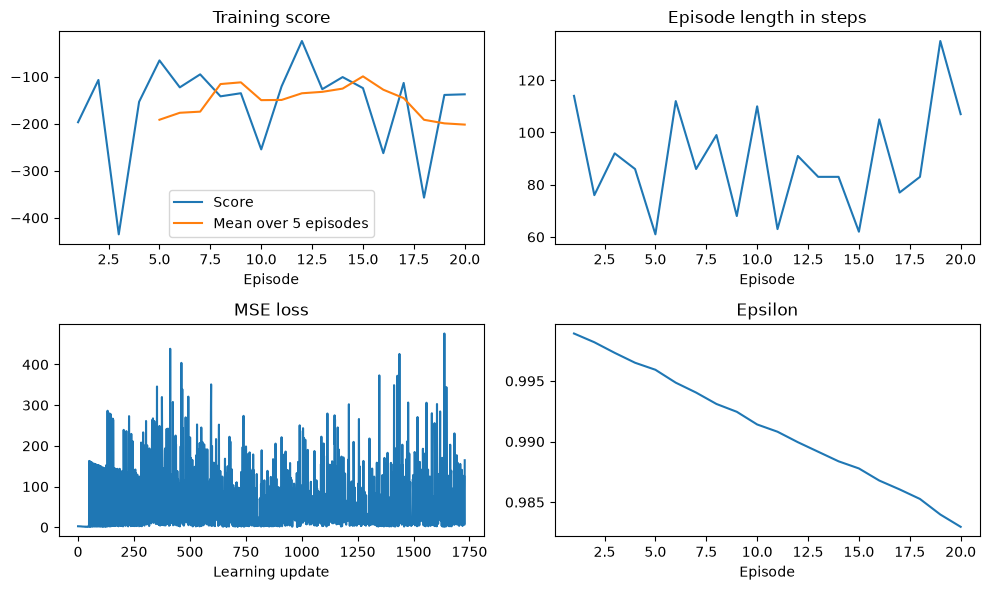

In [23]:
episodes = np.arange(1, len(training_scores) + 1)
window = min(5, len(training_scores))
moving_average = np.convolve(training_scores, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(episodes, training_scores, label="Score")
axes[0, 0].plot(episodes[window - 1:], moving_average, label=f"Mean over {window} episodes")
axes[0, 0].set_title("Training score")
axes[0, 0].legend()
axes[0, 1].plot(episodes, training_lengths)
axes[0, 1].set_title("Episode length in steps")
axes[1, 0].plot(training_losses)
axes[1, 0].set_title("MSE loss")
axes[1, 0].set_xlabel("Learning update")
axes[1, 1].plot(episodes, training_epsilons)
axes[1, 1].set_title("Epsilon")
for ax in [axes[0, 0], axes[0, 1], axes[1, 1]]:
    ax.set_xlabel("Episode")
plt.tight_layout()
plt.show()


## Saving the trial weights

We save this short run locally so the weights can be loaded later. The checkpoint includes the network sizes and seed. It is a trial checkpoint, so the checkpoints folder is ignored by Git.

We also reload the file and check that its weights match the network.

In [24]:
Path("checkpoints").mkdir(exist_ok=True)
checkpoint_path = Path("checkpoints/dqn_short_run.pt")
torch.save({
    "model_state_dict": q_network.state_dict(),
    "state_size": int(state_size),
    "action_size": int(action_size),
    "hidden_size": HIDDEN_SIZE,
    "seed": SEED,
    "episodes": TRAIN_EPISODES,
    "training_steps": total_steps,
}, checkpoint_path)

saved = torch.load(checkpoint_path, weights_only=True)
assert all(
    torch.equal(weight, saved["model_state_dict"][name])
    for name, weight in q_network.state_dict().items()
)
print("Trial weights saved and checked:", checkpoint_path)


Trial weights saved and checked: checkpoints/dqn_short_run.pt


## Next step

The first short training run is ready. Next we add regular evaluation without exploration, save the best evaluated model and increase the training budget.

The final evaluation still needs 100 episodes, several seeds and at least one comparison of settings.